In [ ]:
!pip -q install tensorflow matplotlib scikit-learn

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("Setup completed successfully!")

TensorFlow version: 2.21.0
Setup completed successfully!


In [ ]:
!pip -q install kagglehub

import kagglehub
import os

dataset_path = kagglehub.dataset_download("msambare/fer2013")

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)
print("Folders:", os.listdir(dataset_path))

Using Colab cache for faster access to the 'fer2013' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/fer2013
Folders: ['test', 'train']


In [ ]:
import tensorflow as tf

IMG_SIZE = 48
BATCH_SIZE = 64

train_dir = os.path.join(dataset_path, "train")
test_dir = os.path.join(dataset_path, "test")

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=42
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print("Expression classes:", class_names)

Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 28709 files belonging to 7 classes.
Using 5741 files for validation.
Found 7178 files belonging to 7 classes.
Expression classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


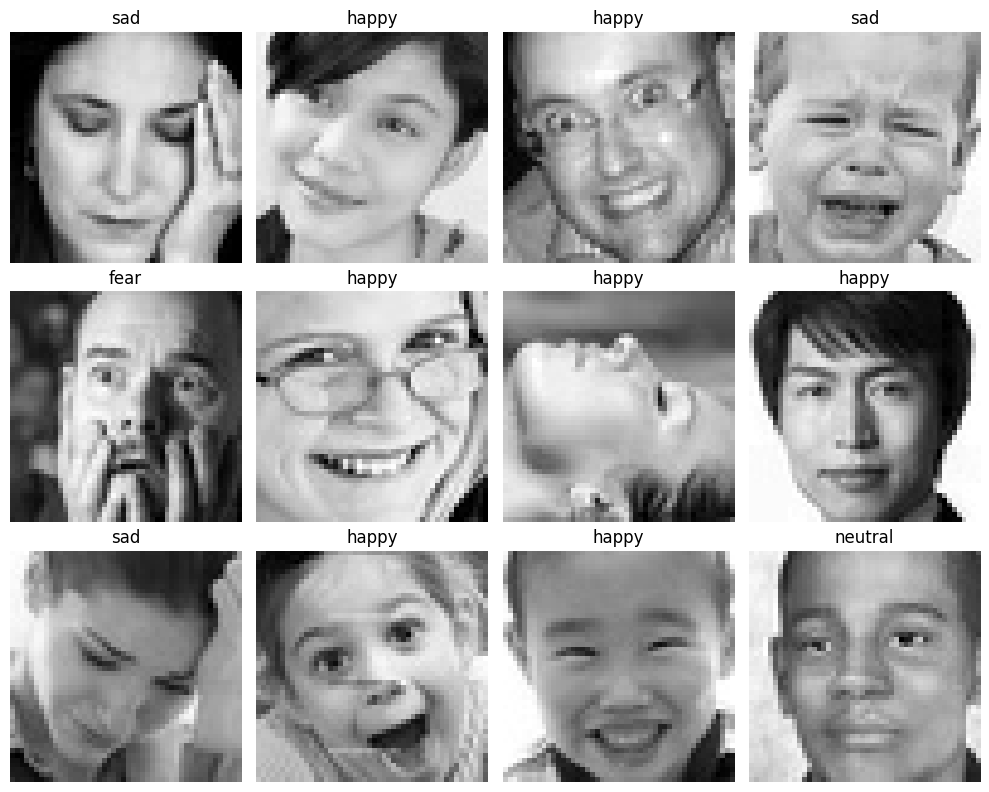

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)

        image = images[i].numpy().squeeze()
        label = class_names[labels[i].numpy()]

        plt.imshow(image, cmap="gray")
        plt.title(label)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def normalize_images(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

train_data = (
    train_ds
    .map(normalize_images, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

val_data = (
    val_ds
    .map(normalize_images, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

test_data = (
    test_ds
    .map(normalize_images, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

print("Dataset normalization completed!")

Dataset normalization completed!


In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(48, 48, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(7, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,847 (1.36 MB)

 Trainable params: 355,847 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 105s 283ms/step - accuracy: 0.2949 - loss: 1.7395 - val_accuracy: 0.3952 - val_loss: 1.5658
Epoch 2/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 83s 232ms/step - accuracy: 0.4163 - loss: 1.5135 - val_accuracy: 0.4576 - val_loss: 1.4124
Epoch 3/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 84s 235ms/step - accuracy: 0.4732 - loss: 1.3810 - val_accuracy: 0.4858 - val_loss: 1.3295
Epoch 4/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 84s 233ms/step - accuracy: 0.5040 - loss: 1.3032 - val_accuracy: 0.5018 - val_loss: 1.3250
Epoch 5/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 84s 233ms/step - accuracy: 0.5339 - loss: 1.2400 - val_accuracy: 0.5262 - val_loss: 1.2430
Epoch 6/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 83s 232ms/step - accuracy: 0.5567 - loss: 1.1774 - val_accuracy: 0.5372 - val_loss: 1.2254
Epoch 7/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 83s 232ms/step - accuracy: 0.5724 - loss: 1.1351 - val_accuracy: 0.5370 - val_loss: 1.2312
Epoch 8/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 85s 236ms/step - accuracy: 0.5901 - loss: 

In [ ]:
test_loss, test_accuracy = model.evaluate(test_data)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

113/113 ━━━━━━━━━━━━━━━━━━━━ 16s 144ms/step - accuracy: 0.5419 - loss: 1.2002
Test Loss: 1.2002
Test Accuracy: 54.19%


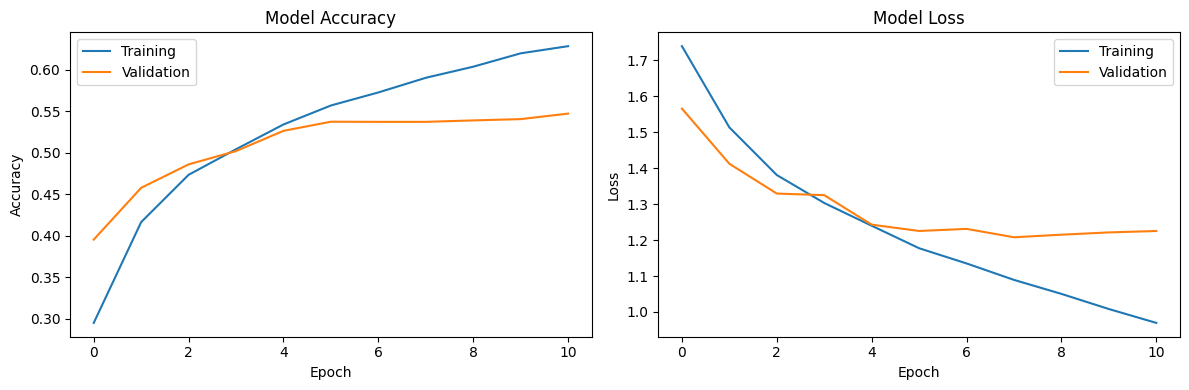

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(test_data)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

113/113 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step - accuracy: 0.5419 - loss: 1.2002
Test Loss: 1.2002
Test Accuracy: 54.19%


113/113 ━━━━━━━━━━━━━━━━━━━━ 8s 72ms/step
              precision    recall  f1-score   support

       angry       0.42      0.46      0.44       958
     disgust       0.79      0.10      0.18       111
        fear       0.40      0.26      0.32      1024
       happy       0.70      0.81      0.75      1774
     neutral       0.49      0.49      0.49      1233
         sad       0.41      0.47      0.44      1247
    surprise       0.72      0.67      0.70       831

    accuracy                           0.54      7178
   macro avg       0.56      0.46      0.47      7178
weighted avg       0.54      0.54      0.53      7178



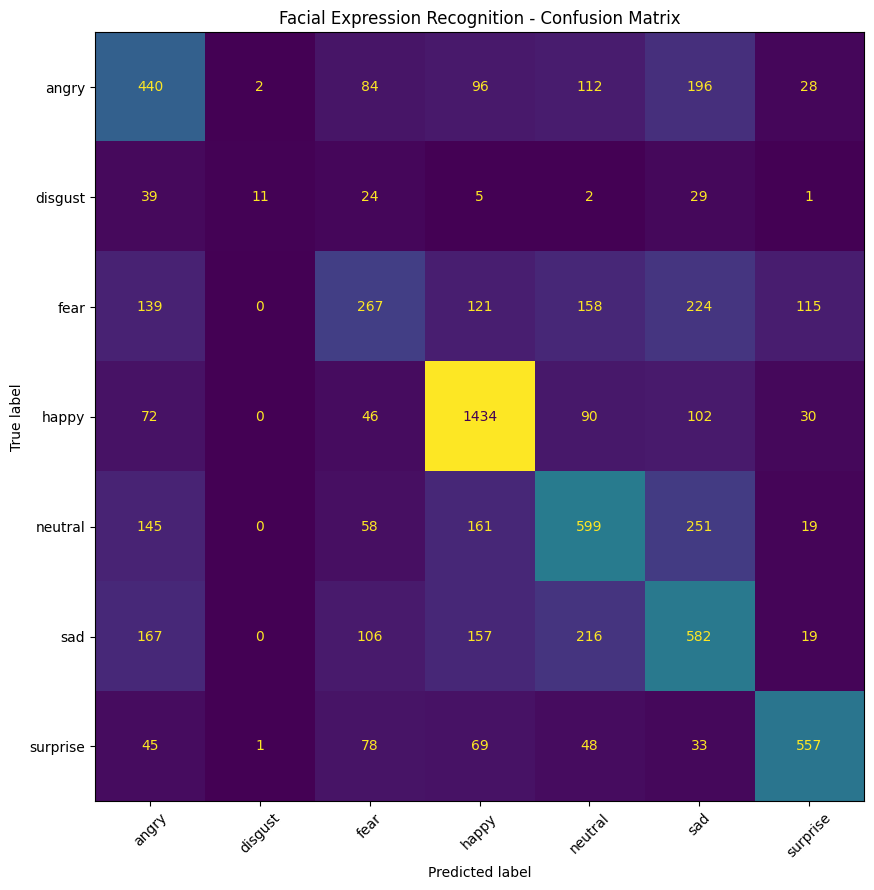

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Get actual labels
y_true = np.concatenate([labels.numpy() for images, labels in test_data])

# Predict expressions
y_probs = model.predict(test_data)
y_pred = np.argmax(y_probs, axis=1)

# Print performance for each expression
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

# Display confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 9))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Facial Expression Recognition - Confusion Matrix")
plt.tight_layout()
plt.show()

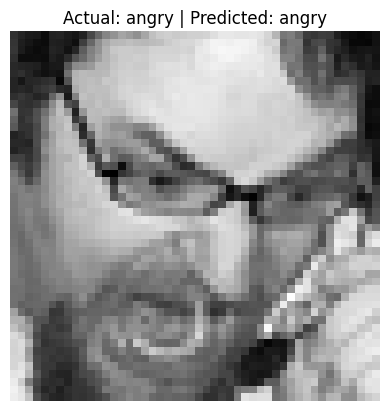

Predicted expression: angry
Model confidence: 29.33%


In [ ]:
images, labels = next(iter(test_data))

i = 0
prediction_probs = model.predict(images[i:i+1], verbose=0)[0]
predicted_id = int(np.argmax(prediction_probs))

plt.imshow(images[i].numpy().squeeze(), cmap="gray")
plt.title(
    f"Actual: {class_names[int(labels[i])]} | "
    f"Predicted: {class_names[predicted_id]}"
)
plt.axis("off")
plt.show()

print("Predicted expression:", class_names[predicted_id])
print(f"Model confidence: {prediction_probs[predicted_id] * 100:.2f}%")

In [ ]:
model.save("facial_expression_model.keras")
print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files
files.download("facial_expression_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

model.save("/content/facial_expression_model.keras")

print(
    "Model size:",
    round(os.path.getsize("/content/facial_expression_model.keras") / (1024 * 1024), 2),
    "MB"
)

Model size: 4.12 MB


In [ ]:
from google.colab import files

files.download("/content/facial_expression_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import requests
import zipfile
from pathlib import Path
from google.colab import files

# Create a folder for sample images
folder = Path("/content/sample_faces")
folder.mkdir(exist_ok=True)

# Sample portrait image URLs
image_urls = {
    "test_face_1.jpg":
        "https://images.unsplash.com/photo-1500648767791-00dcc994a43e?w=600",
    "test_face_2.jpg":
        "https://images.unsplash.com/photo-1534528741775-53994a69daeb?w=600",
    "test_face_3.jpg":
        "https://images.unsplash.com/photo-1506794778202-cad84cf45f1d?w=600"
}

# Download the images
for filename, url in image_urls.items():
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    (folder / filename).write_bytes(response.content)
    print("Downloaded:", filename)

# Put all images into a ZIP file
zip_path = "/content/sample_faces.zip"

with zipfile.ZipFile(zip_path, "w") as zip_file:
    for image_path in folder.iterdir():
        zip_file.write(image_path, arcname=image_path.name)

print("All sample images downloaded!")
files.download(zip_path)

Downloaded: test_face_1.jpg
Downloaded: test_face_2.jpg
Downloaded: test_face_3.jpg
All sample images downloaded!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>